Data Analysis

Minimum of N_max at ε ≈ 0.1:  N_max = 496.5119


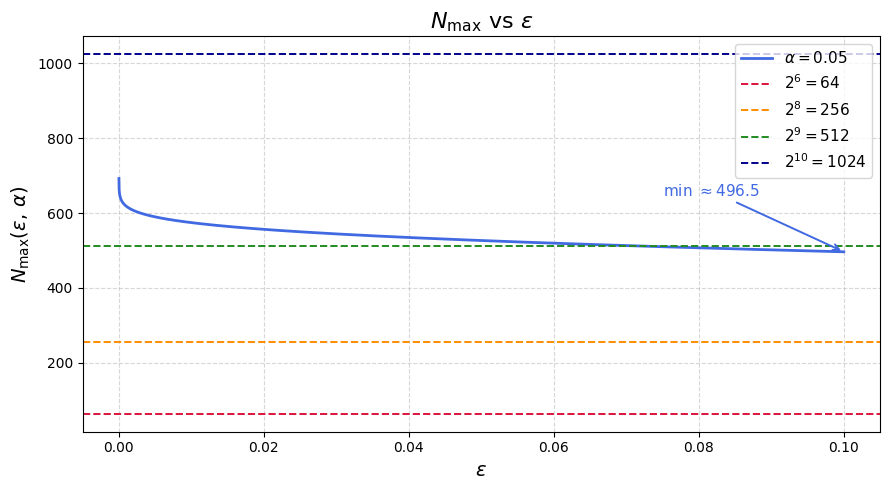

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ── Function ──────────────────────────────────────────────────────────────────
def N_max(epsilon, alpha):
    return (32 / (1 - 2 * np.sin(np.pi / 14)) ** 2) \
           * np.log((2 / alpha) * np.log2(np.pi / (4 * epsilon)))

# ── Parameters ────────────────────────────────────────────────────────────────
alpha = 0.05

epsilon = np.linspace(1e-6, 0.1, 10_000)

inner = np.log2(np.pi / (4 * epsilon))
mask  = (inner > 0) & ((2 / alpha) * inner > 1)
epsilon = epsilon[mask]

y = N_max(epsilon, alpha)

# ── Print minimum of the curve at epsilon ≈ 0.1 ───────────────────────────────
min_val = y[-1]
print(f"Minimum of N_max at ε ≈ 0.1:  N_max = {min_val:.4f}")

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(epsilon, y, color="royalblue", linewidth=2, label=rf"$\alpha = {alpha}$")

# ── Annotate minimum ──────────────────────────────────────────────────────────
ax.annotate(
    rf"min $\approx {min_val:.1f}$",
    xy        = (epsilon[-1], min_val),
    xytext    = (epsilon[-1] - 0.025, min_val + 150),
    fontsize  = 11,
    color     = "royalblue",
    arrowprops= dict(arrowstyle="->", color="royalblue", lw=1.4),
)

# ── Horizontal lines at 2^6, 2^8, 2^9, 2^10 ──────────────────────────────────
powers     = [6, 8, 9, 10]
hline_colors = ["crimson", "darkorange", "forestgreen", "darkblue"]

for p, c in zip(powers, hline_colors):
    val = 2 ** p
    ax.axhline(y=val, color=c, linewidth=1.4, linestyle="--",
               label=rf"$2^{{{p}}} = {val}$")

ax.set_xlabel(r"$\epsilon$",                          fontsize=14)
ax.set_ylabel(r"$N_{\max}(\epsilon,\, \alpha)$",      fontsize=14)
ax.set_title(r"$N_{\max}$ vs $\epsilon$",             fontsize=16)

ax.legend(fontsize=11, loc="upper right")
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [4]:
import re
import numpy as np

def parse_iqae_file(filepath):
    """
    Parse an IQAE frontier data export file.
    Extracts: N_SHOTS, epsilon, p_star
    
    Returns:
        N_shots  : int
        epsilon  : np.ndarray
        p_star   : np.ndarray
    """
    N_shots  = None
    epsilons = []
    p_stars  = []

    with open(filepath, "r") as f:
        lines = f.readlines()

    in_data_section = False

    for line in lines:
        line = line.strip()

        # ── Extract N_SHOTS from header ───────────────────────────────────────
        if line.startswith("N_SHOTS:"):
            N_shots = int(line.split(":")[1].strip())

        # ── Detect start of data section ──────────────────────────────────────
        if line.startswith("epsilon | p_star"):
            in_data_section = True
            continue  # skip the header row

        # ── Skip separator line ───────────────────────────────────────────────
        if in_data_section and set(line) <= set("-"):
            continue

        # ── Parse data rows ───────────────────────────────────────────────────
        if in_data_section and "|" in line:
            parts = [p.strip() for p in line.split("|")]
            epsilons.append(float(parts[0]))
            p_stars.append(float(parts[1]))

    return N_shots, np.array(epsilons), np.array(p_stars)


# ── Usage ─────────────────────────────────────────────────────────────────────
N_shots, epsilon, p_star = parse_iqae_file("data50.txt")